In [2]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [3]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

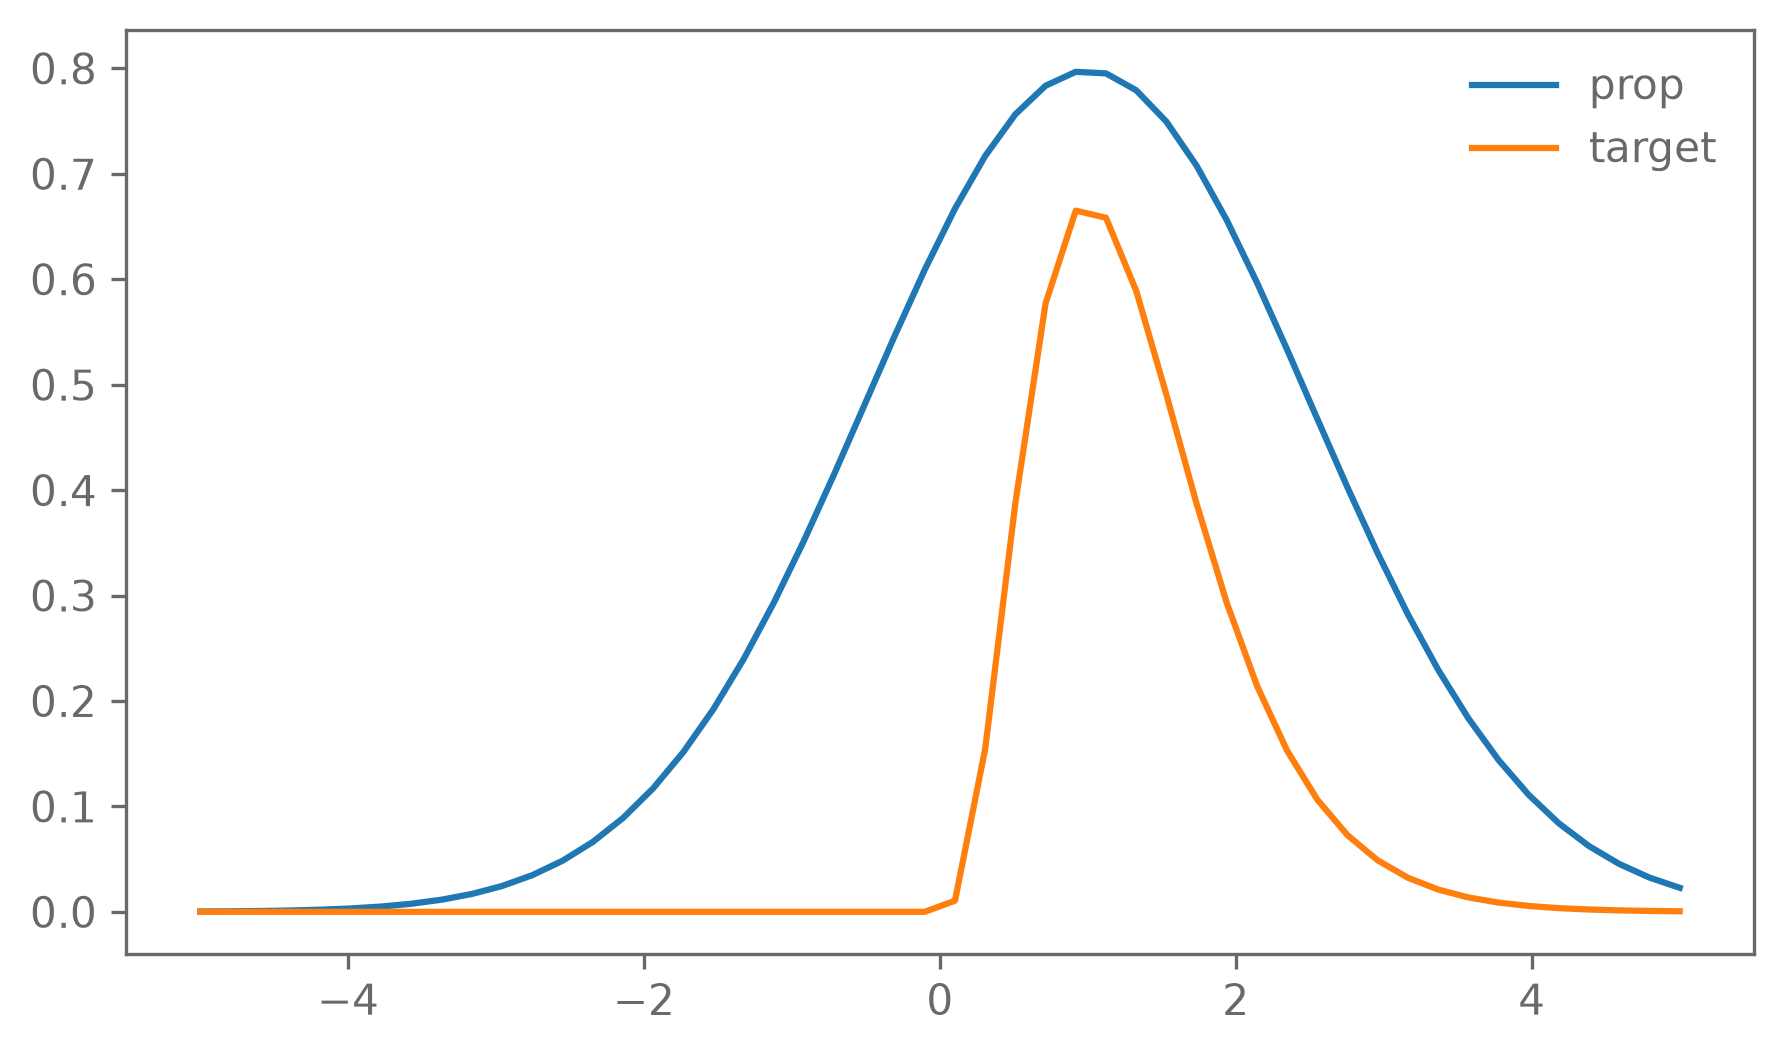

In [4]:
proposal_distr = scipy.stats.norm(loc=1,scale=1.5)
target_distr = scipy.stats.gamma(a=4, scale=1/3)
M = 3
x = np.linspace(-5.0,5.0)
plt.plot(x,M * proposal_distr.pdf(x),label='prop')
plt.plot(x,target_distr.pdf(x),label='target')
plt.legend()

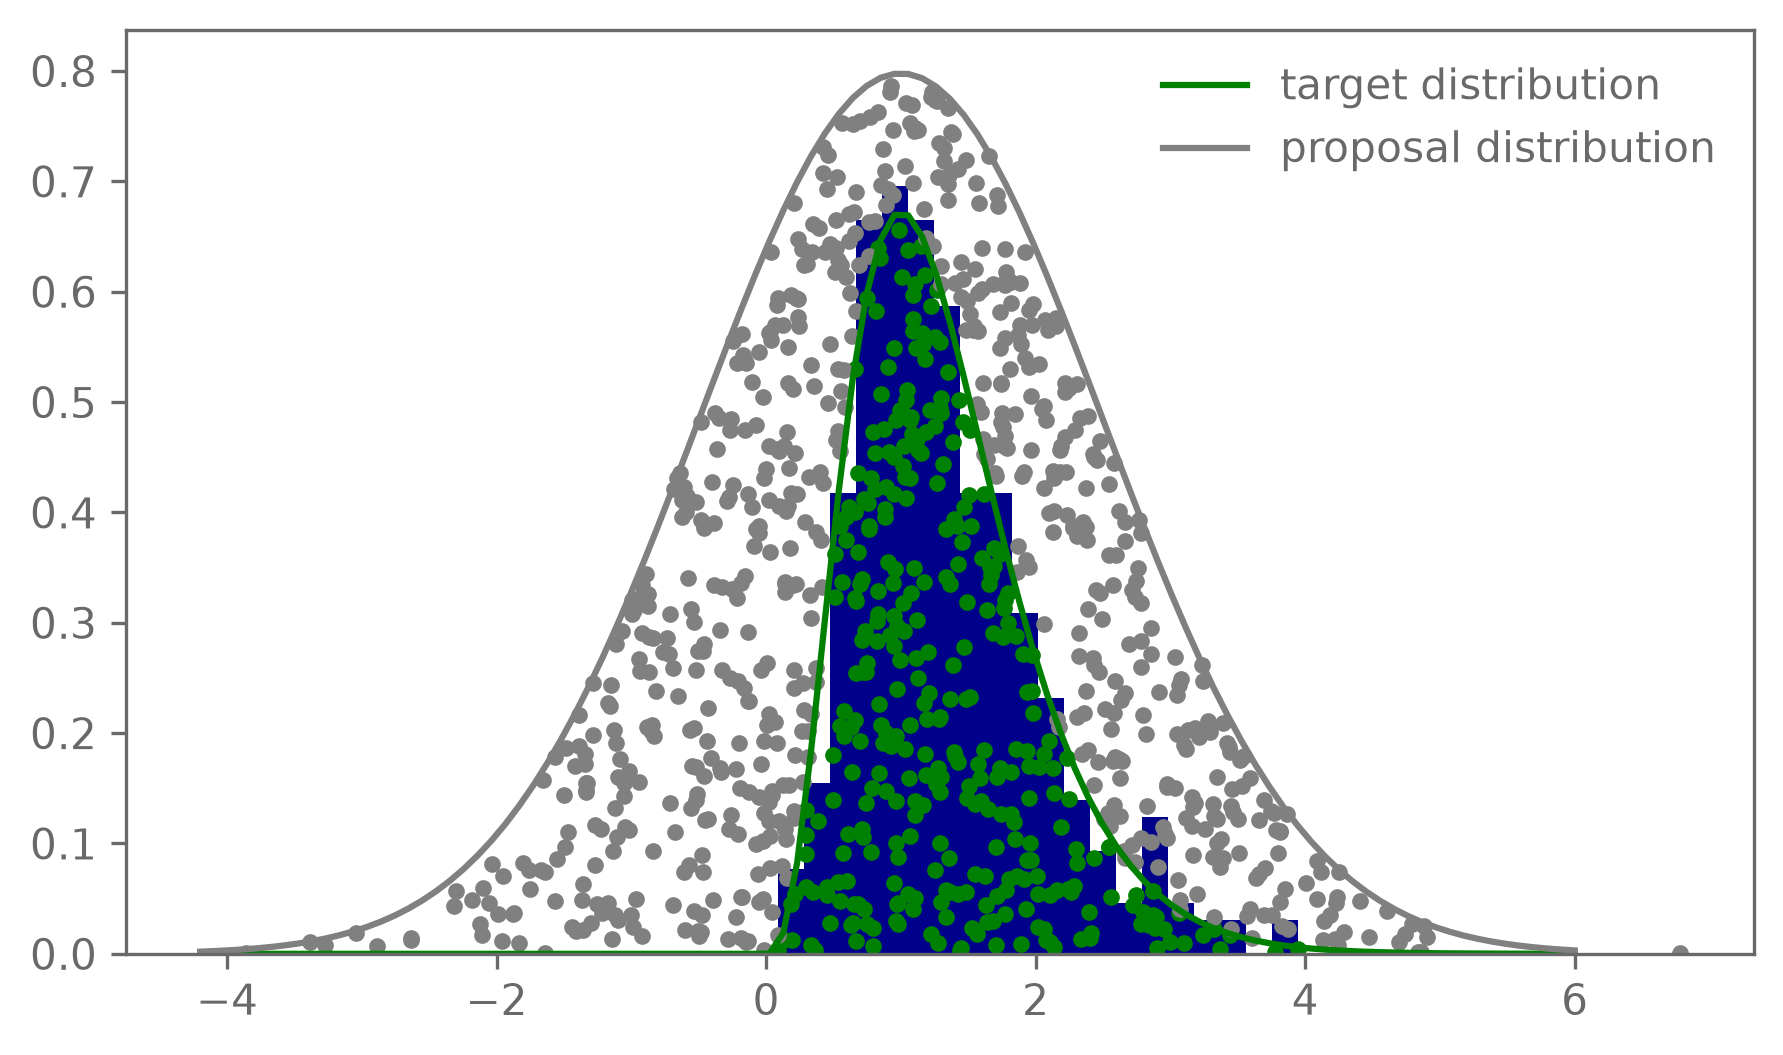

In [51]:
def rejection_sampling(n):
    samples = 0
    accepted_y = []
    accepted_x = []
    rejected_y = []
    rejected_x = []
    while samples < n:
        x = proposal_distr.rvs(size=1)

        g = M * proposal_distr.pdf(x)
        f = target_distr.pdf(x)
        u = np.random.uniform(0.0,g,size=1)
        samples += 1

        if u < f:
            accepted_x.append(x)
            accepted_y.append(u)
        else:
            rejected_x.append(x)
            rejected_y.append(u)
    return accepted_x,accepted_y,rejected_x,rejected_y

n=1000
accepted_x, accepted_y, rejected_x, rejected_y = rejection_sampling(n)
x = np.linspace(-4.2,6.0,100)
counts, bins = np.histogram(accepted_x,20,density=True)
np.random.seed(42)

plt.plot(accepted_x,accepted_y,ls=' ',marker ='.',color='green')
plt.plot(rejected_x,rejected_y,ls=' ',marker='.',color='grey')
plt.plot(x,target_distr.pdf(x),color='green',label='target distribution')
plt.plot(x, M * proposal_distr.pdf(x), color='grey',label='proposal distribution')
plt.stairs(counts,bins,color='darkblue',fill=True)
plt.legend()


### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [52]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

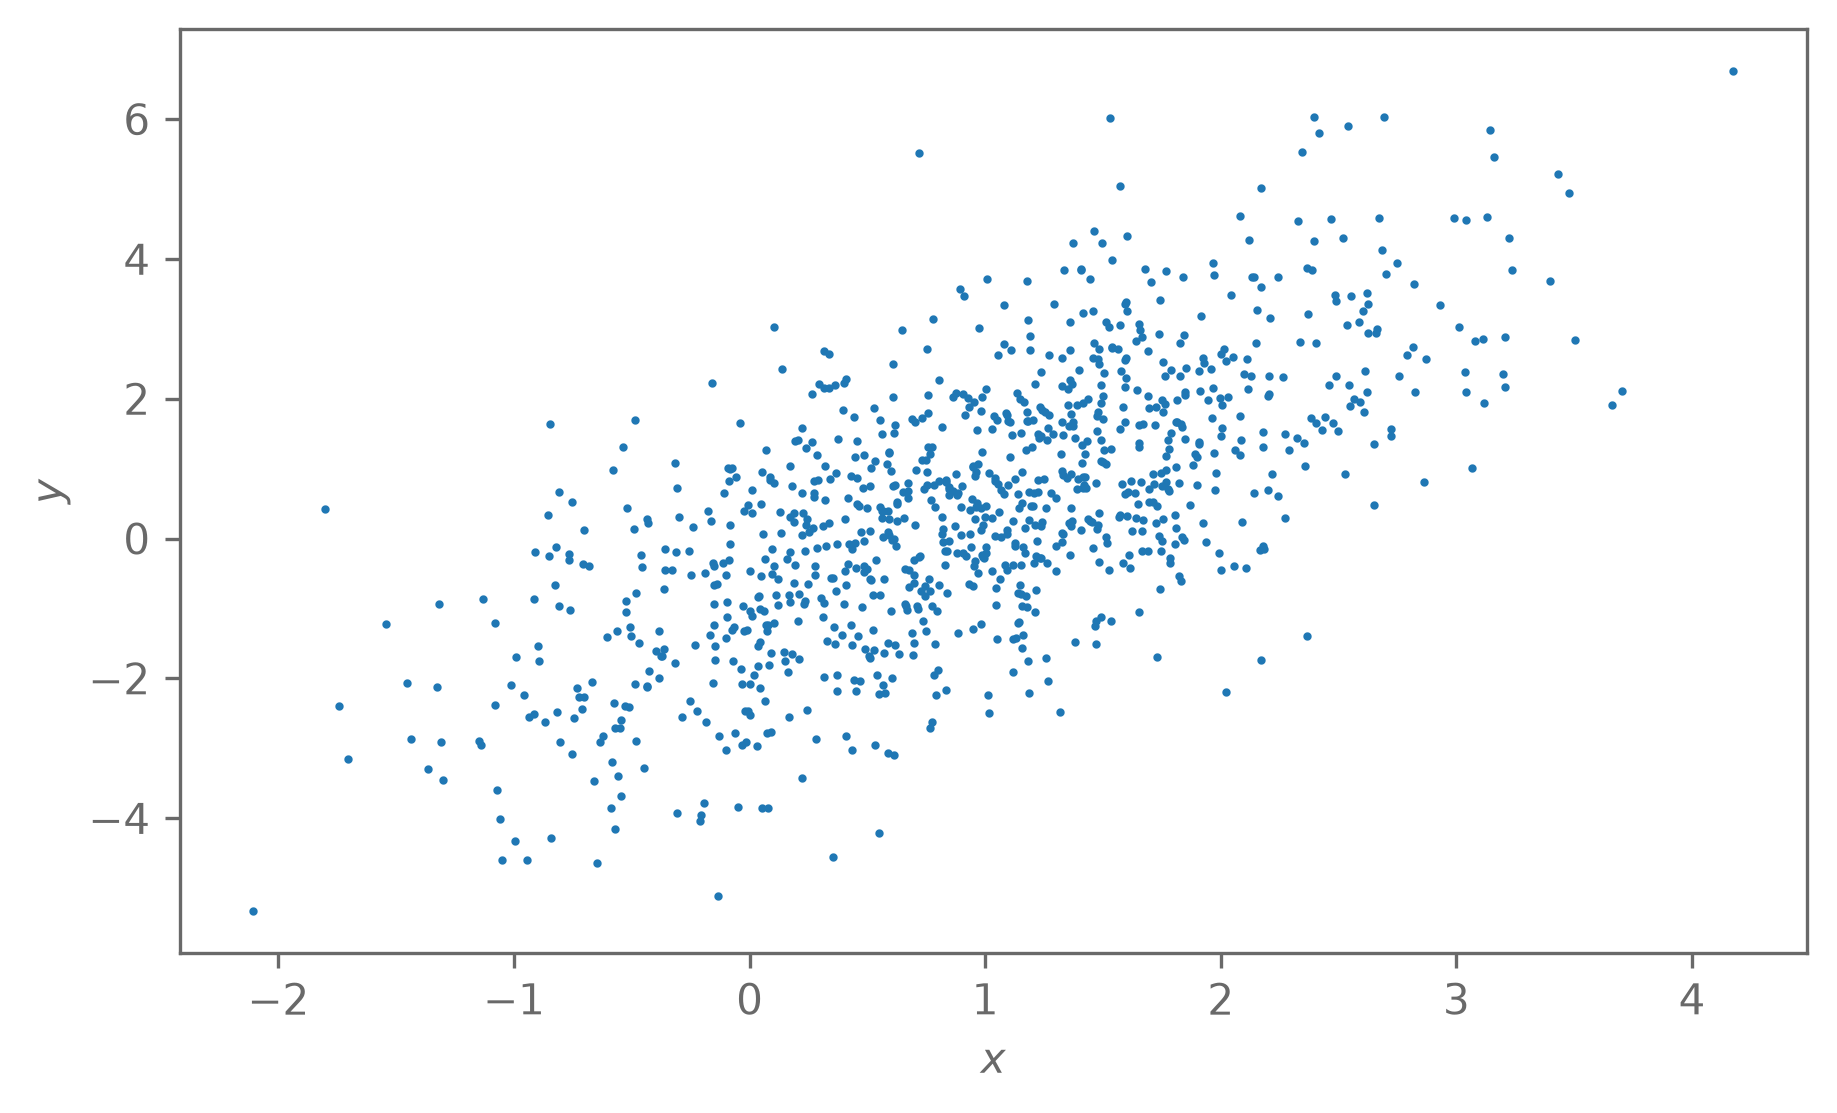

In [53]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");